# Avance 5. Ensambles y modelo final

**Equipo 51** · Proyecto Integrador, Maestría en Inteligencia Artificial Aplicada (MNA), TC5035
**Proyecto:** AI Co-Pilot Video-to-SOP (patrocinador: Alignity)

## 0. Introducción

**Objetivos del avance**

- **3.5** Construir ensambles con las tres familias principales (bagging, boosting y combinación de modelos distintos) y compararlos, con la misma métrica y el mismo protocolo de validación, contra el modelo individual elegido en el avance 4.
- **3.6** Elegir el modelo final del producto con argumentos de desempeño, estabilidad, calibración e interpretabilidad, y fijar el umbral de operación que el avance 4 dejó pendiente.

**De dónde venimos.** El avance 4 comparó ocho modelos individuales de seis familias y eligió la **SVM (RBF)** calibrada (`C ≈ 32.8`, `gamma ≈ 0.0158`) como modelo individual final: AUC-PR 0.599 en validación cruzada agrupada por grabación (desviación 0.024, la menor de los ocho) y 0.686 en validación. Dejó dos tareas explícitas para este avance:

1. **Los ensambles.** El avance 4 excluyó a propósito bosques aleatorios, *bagging*, *boosting* y LightGBM: "se reservan para el avance 5". También fijó los **tres mejores individuales con sus hiperparámetros** (MLP, SVM y regresión logística) para que este avance no los volviera a elegir: son la base del *voting* y del *stacking*.
2. **El umbral de operación.** Su conclusión 8 dice: *"el umbral de operación del producto deberá elegirse en el avance 5 con probabilidades recalibradas"*, porque la SVM quedaba con un recall de 0.80 (contra 0.87 del baseline) y esa diferencia era efecto del umbral, no del orden de las probabilidades.

**Preguntas guía**

1. ¿Un ensamble supera al mejor modelo individual por más que la variación entre pliegues?
2. ¿Qué familia aporta: bagging (reduce varianza), boosting (reduce sesgo) o la combinación de modelos distintos (aprovecha que se equivocan en pasos diferentes)?
3. ¿El ensamble cuesta más de lo que aporta, en tiempo de CPU y en interpretabilidad, para un producto que corre local en una GPU de 8 GB y a costo cero (ADR-011)?
4. ¿Con qué probabilidades calibradas y qué umbral debe operar el producto, y qué carga de revisión humana implica?

**Estructura.** Secciones 4 y 5: ensambles homogéneos (bagging) y secuenciales (boosting). Sección 6: combinación de los tres individuales fijados en el avance 4. Sección 7: comparación global con prueba por pliegues apareados. Sección 8: qué variables sostienen al ganador. Sección 9: calibración y umbral de operación. Secciones 10 y 11: decisión final y conclusiones.

> **Resultado de una línea, para que el lector sepa qué va a encontrar:** ninguno de los diez ensambles supera al modelo individual del avance 4 por más que la variación entre pliegues. El único que se le acerca —y lo supera en 4 de 5 pliegues y en Brier— es el *voting* suave de los tres individuales (+0.013 de AUC-PR), y la regla de decisión fijada antes de mirar los resultados no lo considera suficiente. El avance deja un modelo final confirmado, un umbral de operación con costo explícito y una explicación de *por qué* los ensambles no ayudan en este problema, que es información tan útil como un ensamble ganador.

## 1. Configuración del entorno

Las características se importan de `sopvid.features`, sin cambios: la matriz es la misma del avance 4 (35 columnas seleccionadas más `duration`). Las funciones auxiliares de evaluación son las de los avances 3 y 4 (sección 3) y se redefinen aquí para que el notebook se ejecute solo. `lightgbm` se agrega a las dependencias `ml` del paquete en este avance, con versión fijada.

In [1]:
import re
import time
import warnings

import lightgbm as lgb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
    VotingClassifier,
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    fbeta_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

import sopvid
from sopvid.features import data
from sopvid.features import engineering as fe
from sopvid.features import preprocessing as pp

%matplotlib inline
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = fe.SEED  # 51, igual que en los avances 1 a 4
np.random.seed(SEED)
CV = GroupKFold(n_splits=5)  # pliegues por grabación, como en los avances 2 a 4
N_JOBS = -1                  # no cambia los resultados
T_START = time.perf_counter()

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 240)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
BLUE, RED, GREEN, GRAY, PURPLE = "#2c7fb8", "#c0392b", "#2ca25f", "#7f7f7f", "#756bb1"

print("sopvid", sopvid.__version__, "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| sklearn", sklearn.__version__, "| lightgbm", lgb.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

sopvid 0.1.0 | pandas 3.0.6 | numpy 2.4.6 | scipy 1.17.1 | sklearn 1.9.1 | lightgbm 4.6.0 | matplotlib 3.11.2 | seaborn 0.13.2


## 2. Datos: la misma matriz del avance 4

Sin cambios de datos, para que la comparación sea limpia: las 35 columnas seleccionadas en el avance 2 más `duration` (conclusión 2 del avance 3), con el mismo `build_features`, la misma partición y la misma prevalencia. `rec_duration` se conserva en la matriz principal y se deja la variante sin ella (35 columnas) para el finalista: el avance 4 midió que su aporte es real, y su ausencia es una decisión de despliegue, no de modelado.

In [2]:
raw = data.load_raw()
steps = data.build_step_table(raw.complete, raw.errors_raw)
parts = pp.split_steps(steps, raw.splits)
graphs = data.load_task_graphs(steps["activity_name"].unique())

# Los dos pipelines se ajustan SOLO con entrenamiento y transforman validación.
fs = fe.build_features(parts["train"], parts["val"], video_info=raw.video_info, task_graphs=graphs)
fs_all = fe.build_features(parts["train"], parts["val"], video_info=raw.video_info,
                           task_graphs=graphs, select=False)

COLS = [*fs.X_train.columns, "duration"]
assert np.allclose(fs_all.X_train[fs.X_train.columns], fs.X_train)

X_tr, X_va = fs_all.X_train[COLS], fs_all.X_test[COLS]
y_tr, y_va = fs_all.y_train, fs_all.y_test
g_tr = parts["train"].loc[X_tr.index, "recording_id"]

Xb_tr, Xb_va = X_tr.drop(columns="rec_duration"), X_va.drop(columns="rec_duration")
PREV_TR, PREV_VA = y_tr.mean(), y_va.mean()

pd.DataFrame({
    "grabaciones": [g_tr.nunique(), parts["val"].loc[X_va.index, "recording_id"].nunique()],
    "pasos ejecutados": [len(X_tr), len(X_va)],
    "columnas (con / sin rec_duration)": [f"{X_tr.shape[1]} / {Xb_tr.shape[1]}",
                                          f"{X_va.shape[1]} / {Xb_va.shape[1]}"],
    "% con error": [100 * PREV_TR, 100 * PREV_VA],
    "faltantes": [int(X_tr.isna().sum().sum()), int(X_va.isna().sum().sum())],
}, index=["entrenamiento", "validación"])

,grabaciones,pasos ejecutados,columnas (con / sin rec_duration),% con error,faltantes
entrenamiento,213,2987,36 / 35,24.908,0
validación,62,884,36 / 35,37.783,0


**Observación** Las particiones coinciden exactamente con el avance 4 (2,987 pasos de entrenamiento en 213 grabaciones, 884 de validación en 62, sin faltantes), así que las cifras de ambos avances son comparables sin reservas. La prevalencia sigue siendo distinta (24.9 % contra 37.8 %) y por eso, como en los avances 3 y 4, el AUC-PR se reporta junto con el *lift* (AUC-PR / prevalencia).

## 3. Métrica y protocolo de evaluación

Se conservan **sin cambios** la métrica principal y el protocolo de los avances 3 y 4 (si cambiaran, no se podría comparar con lo ya entregado):

| Rol | Métrica | Por qué (avances 3 y 4) |
|---|---|---|
| **Principal** | **AUC-PR** (*average precision*) | Desbalance de 25 %; el modelo **ordena** pasos para revisión humana. Su valor de azar es la prevalencia. |
| Secundaria | **F2** al umbral de operación | Pesa el recall cuatro veces más que la precisión: dejar pasar un error cuesta más que una revisión de más. |
| Secundaria | **Recall y precisión** | Lo que entiende el experto. |
| Diagnóstico | ROC-AUC, Brier, *lift*, log loss | Comparabilidad entre avances y calidad de las probabilidades. |
| Protocolo | `GroupKFold(5)` por `recording_id` | Un mismo video no puede estar en entrenamiento y en validación: las características de grabación lo harían trivial. |
| Umbral | Elegido con probabilidades **fuera de pliegue de entrenamiento** | Validación no participa en ninguna decisión. |
| Comparación | **Por pliegues apareados** (nuevo en este avance) | Dos modelos casi empatados en la media pueden diferir siempre en el mismo sentido; eso es información, y una media sola la esconde. |

**Lo que sí es nuevo.** El avance 4 comparaba cada modelo contra el mejor *de su propia tabla*. Aquí, como los ensambles combinan a los individuales, todas las comparaciones se hacen contra los **tres individuales del avance 4 recalculados en este mismo notebook** con su configuración ya fijada (sección 3.1): si un ensamble gana, gana contra la misma vara.

In [3]:
def scores(y, p, thr):
    # Métricas de la sección 3: AUC-PR (principal) y las secundarias al umbral de operación.
    yhat = (p >= thr).astype(int)
    return {
        "AUC-PR": average_precision_score(y, p),
        "ROC-AUC": roc_auc_score(y, p),
        "F2": fbeta_score(y, yhat, beta=2, zero_division=0),
        "Recall": recall_score(y, yhat, zero_division=0),
        "Precisión": precision_score(y, yhat, zero_division=0),
        "% marcados": 100 * yhat.mean(),
        "Brier": brier_score_loss(y, p),
        "log loss": log_loss(y, np.clip(p, 1e-15, 1 - 1e-15)),
    }


def oof_proba(model, X, y, groups=g_tr):
    # Probabilidades fuera de pliegue: cada paso se predice con un modelo que no vio su grabación.
    return cross_val_predict(clone(model), X, y, groups=groups, cv=CV, method="predict_proba")[:, 1]


def cv_ap(model, X, y, groups=g_tr):
    # AUC-PR por pliegue (media y desviación), como en los avances 2 a 4.
    return np.array([average_precision_score(y.iloc[te],
                                             clone(model).fit(X.iloc[tr], y.iloc[tr])
                                             .predict_proba(X.iloc[te])[:, 1])
                     for tr, te in CV.split(X, y, groups)])


def f2_threshold(y, p):
    # Umbral que maximiza F2 sobre probabilidades fuera de pliegue de ENTRENAMIENTO.
    prec, rec, thr = precision_recall_curve(y, p)
    f2 = 5 * prec * rec / np.clip(4 * prec + rec, 1e-12, None)
    return float(thr[np.argmax(f2[:-1])])


def evaluate(model, Xtr=None, Xva=None):
    # Protocolo de la sección 3 para un modelo; validación solo se predice al final.
    Xtr = X_tr if Xtr is None else Xtr
    Xva = X_va if Xva is None else Xva
    t0 = time.perf_counter(); fitted = clone(model).fit(Xtr, y_tr); fit_s = time.perf_counter() - t0
    folds = cv_ap(model, Xtr, y_tr)
    p_oof = oof_proba(model, Xtr, y_tr)
    thr = f2_threshold(y_tr, p_oof)
    t0 = time.perf_counter(); p_va = fitted.predict_proba(Xva)[:, 1]; pred_s = time.perf_counter() - t0
    return {"model": fitted, "folds": folds, "p_oof": p_oof, "p_va": p_va, "thr": thr,
            "fit_ms": 1000 * fit_s, "pred_ms_1k": 1000 * pred_s / len(Xva) * 1000,
            "cv": scores(y_tr, p_oof, thr), "val": scores(y_va, p_va, thr)}


def row(r):
    # Fila de las tablas comparativas, con las columnas de los avances 3 y 4.
    return {"AUC-PR CV": r["folds"].mean(), "desv. CV": r["folds"].std(),
            "AUC-PR val": r["val"]["AUC-PR"], "lift val": r["val"]["AUC-PR"] / PREV_VA,
            "ROC-AUC val": r["val"]["ROC-AUC"], "F2 val": r["val"]["F2"],
            "Recall val": r["val"]["Recall"], "Precisión val": r["val"]["Precisión"],
            "umbral F2": r["thr"], "Brier CV": r["cv"]["Brier"],
            "entrenamiento (ms)": r["fit_ms"]}


def paired(r_a, r_b):
    # Comparación por pliegues apareados: ¿a gana a b siempre, o solo en promedio?
    d = r_a["folds"] - r_b["folds"]
    return {"Δ CV": d.mean(), "desv. de Δ": d.std(), "pliegues a favor": int((d > 1e-9).sum()),
            "pliegues en contra": int((d < -1e-9).sum())}


def tabla(resultados, familia):
    t = pd.DataFrame({n: row(r) for n, r in resultados.items()}).T
    t.insert(0, "familia", familia)
    return t.sort_values("AUC-PR CV", ascending=False)

### 3.1 Los tres individuales del avance 4, recalculados

El avance 4 fijó estos tres en su sección 6.4, con los hiperparámetros ya ajustados, para que este avance no los volviera a elegir. Se recalculan aquí porque son la base del *voting* y del *stacking*, y porque son la vara contra la que se mide si el ensamble aporta algo.

In [4]:
# Hiperparámetros fijados en la sección 6.4 del avance 4, sin volver a ajustarlos.
TOP3 = {
    "MLP": MLPClassifier(alpha=0.2582, early_stopping=True, hidden_layer_sizes=(32, 16),
                         learning_rate_init=0.01001, max_iter=1000, random_state=SEED),
    "SVM (RBF)": CalibratedClassifierCV(SVC(C=32.83, class_weight="balanced", gamma=0.01581,
                                            random_state=SEED), method="sigmoid", cv=3,
                                        ensemble=False),
    "Regresión logística": LogisticRegression(class_weight="balanced", max_iter=5000),
}
FINAL_A4 = "SVM (RBF)"  # modelo individual final del avance 4

# Criterios de desempeño mínimo del avance 3 (sección 4), sin cambios.
MIN_LIFT, MIN_RECALL, MIN_PREC_LIFT = 1.5, 0.70, 1.4
rules = {
    "Regla de orden: order_violation = 1": lambda X: X["order_violation"].to_numpy(),
    "Regla de duración: paso más corto que su típico": lambda X: -X["dur_ratio_step"].to_numpy(),
    "Regla de grabación: video más corto": lambda X: -X["rec_duration"].to_numpy(),
}
ref = pd.DataFrame({n: {"AUC-PR train": average_precision_score(y_tr, f(X_tr)),
                        "AUC-PR val": average_precision_score(y_va, f(X_va))}
                    for n, f in rules.items()}).T
BEST_RULE = ref["AUC-PR train"].idxmax()

t0 = time.perf_counter()
ind_res = {n: evaluate(m) for n, m in TOP3.items()}
print(f"Tres individuales del avance 4 recalculados en {time.perf_counter() - t0:.0f} s")
pd.DataFrame({n: row(r) for n, r in ind_res.items()}).T[["AUC-PR CV", "desv. CV", "AUC-PR val",
                                                         "umbral F2", "Brier CV"]]

Tres individuales del avance 4 recalculados en 6 s


,AUC-PR CV,desv. CV,AUC-PR val,umbral F2,Brier CV
MLP,0.603,0.042,0.729,0.076,0.152
SVM (RBF),0.599,0.024,0.686,0.207,0.158
Regresión logística,0.568,0.045,0.690,0.296,0.190


**Reproducción.** Las cifras coinciden con las del avance 4: MLP 0.603 (allí 0.602), SVM 0.599 (igual) y regresión logística 0.568 (igual), con la misma desviación en los tres casos. La diferencia de una milésima en el MLP es la lotería de los pesos iniciales, que el avance 4 ya había documentado con 10 semillas. Las dos entregas son, por lo tanto, comparables sin reservas: mismo dataset, misma partición, mismo protocolo y mismo entorno. A partir de aquí, "individual" significa una fila de esta tabla.

## 4. Ensambles homogéneos: *bagging*

Los tres entrenan muchos modelos del **mismo tipo** sobre muestras *bootstrap* y promedian. Atacan la **varianza**: un árbol suelto cambia mucho si se mueve una grabación del conjunto, y promediar muchos árboles decorrelacionados la reduce. Son la respuesta natural al diagnóstico del avance 4, donde el árbol de decisión era el más inestable entre pliegues (desviación 0.066) y no superaba la mejor regla simple.

| Modelo | Qué aporta frente a un árbol suelto | Configuración y por qué |
|---|---|---|
| **Random Forest** | *Bagging* + selección aleatoria de variables en cada corte: decorrelaciona los árboles más que el *bagging* puro. | 500 árboles, `min_samples_leaf=3`, `max_features="sqrt"`, `class_weight="balanced_subsample"`: con 36 variables y 25 % de positivos, hojas pequeñas capturan interacciones finas y el peso por submuestra compensa el desbalance. |
| **Extra Trees** | Cortes aleatorios además de variables aleatorias: más varianza por árbol y menos correlación entre ellos. | Mismos 500 árboles y `class_weight="balanced"`. Suele ayudar cuando las variables son ruidosas y continuas, como las de duración. |
| **Bagging (árbol)** | *Bagging* puro sobre un árbol de profundidad 8: el intermedio entre el árbol del avance 4 y el bosque. | 200 estimadores, `max_samples=0.8`, `max_features=0.8`: menos aleatoriedad que el bosque, para aislar cuánto aporta el *bagging* frente a la selección de variables. |

In [5]:
hom = {
    "Random Forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=3, max_features="sqrt",
                                            class_weight="balanced_subsample", random_state=SEED,
                                            n_jobs=N_JOBS),
    "Extra Trees": ExtraTreesClassifier(n_estimators=500, min_samples_leaf=3, max_features="sqrt",
                                        class_weight="balanced", random_state=SEED, n_jobs=N_JOBS),
    "Bagging (árbol)": BaggingClassifier(DecisionTreeClassifier(max_depth=8, class_weight="balanced",
                                                                random_state=SEED),
                                         n_estimators=200, max_samples=0.8, max_features=0.8,
                                         random_state=SEED, n_jobs=N_JOBS),
}
t0 = time.perf_counter()
res_hom = {n: evaluate(m) for n, m in hom.items()}
print(f"3 ensambles de bagging evaluados en {time.perf_counter() - t0:.0f} s")
tabla_hom = tabla(res_hom, "bagging")
tabla_hom

3 ensambles de bagging evaluados en 30 s


,familia,AUC-PR CV,desv. CV,AUC-PR val,lift val,ROC-AUC val,F2 val,Recall val,Precisión val,umbral F2,Brier CV,entrenamiento (ms)
Extra Trees,bagging,0.533,0.054,0.723,1.912,0.787,0.760,0.853,0.529,0.292,0.181,644.203
Random Forest,bagging,0.532,0.059,0.730,1.933,0.797,0.777,0.907,0.493,0.153,0.169,"1,398.492"
Bagging (árbol),bagging,0.473,0.064,0.633,1.677,0.764,0.780,0.991,0.421,0.103,0.190,"4,531.781"


**Interpretación**

- **Los tres quedan por debajo de los individuales.** Extra Trees 0.533, Random Forest 0.532 y *bagging* 0.473 en AUC-PR de CV, contra 0.603 del MLP y 0.599 de la SVM. La caída del *bagging* puro (−0.13 frente al MLP) es la más grande de todo el notebook.
- **Bosque y Extra Trees son indistinguibles.** 0.533 contra 0.532, con desviaciones de 0.054 y 0.059: la diferencia entre ellos es veinte veces menor que su variación entre pliegues. Elegir entre los dos sería elegir ruido.
- **El *bagging* cuesta cinco veces más y aporta menos.** El *bagging* de árboles tarda 4,641 ms en entrenar (contra 662 ms de Extra Trees) y es el peor de la familia: cuando los 200 árboles son profundos y poco decorrelacionados, promediarlos no cancela el error, solo lo reparte.
- **En validación parecen mejores de lo que son.** Random Forest y Extra Trees dan 0.730 y 0.723 de AUC-PR en validación, por encima de la SVM (0.686). Es exactamente el riesgo que el protocolo evita: validación son 62 grabaciones y una sola partición; la CV con 213 grabaciones en 5 pliegues es la señal fiable, y en ella los bosques pierden por 0.07. La regla de no usar validación para elegir se justifica aquí sola.
- **Por qué fallan.** El bosque reduce varianza promediando árboles **decorrelacionados**; con estas 36 variables, casi todos los árboles empiezan cortando por `rec_duration`, `rec_n_steps` o `exec_idx` (sección 8), así que salen correlacionados y el promedio no cancela gran cosa. Además, la relación que hay que aprender es suave (lineal más pocas interacciones): un bosque aproxima esa superficie con escalones y pierde precisión en la zona donde el umbral importa.

## 5. Ensambles secuenciales: *boosting*

Entrenan modelos **uno tras otro**, cada uno sobre el error del anterior. Atacan el **sesgo**: construyen una frontera que ningún modelo suelto puede, a costa de más hiperparámetros y más riesgo de sobreajuste si se pasan de iteraciones. Se incluyen los tres de scikit-learn y **LightGBM**, que el avance 4 reservó explícitamente para este avance.

| Modelo | Qué aporta | Configuración y por qué |
|---|---|---|
| **Gradient Boosting** | *Boosting* clásico con árboles poco profundos: reduce sesgo de forma aditiva. | 300 iteraciones, `learning_rate=0.05`, `max_depth=3`, `subsample=0.8`. El más lento, pero el más transparente. No acepta `class_weight`: el desbalance se compensa con la profundidad y la tasa. |
| **Hist Gradient Boosting** | El *boosting* de scikit-learn con *binning*: mismo sesgo, mucho más rápido y con soporte nativo de desbalance. | 300 iteraciones, `max_leaf_nodes=15`, `class_weight="balanced"`. |
| **LightGBM** | *Boosting* por hojas (*leaf-wise*) con histogramas: el más rápido en tablas de este tamaño. | 300 árboles, `num_leaves=15`, `min_child_samples=20`, `subsample=0.8`, `colsample_bytree=0.8`, `class_weight="balanced"`. Hojas limitadas porque son 2,987 filas: sin ese límite, *leaf-wise* sobreajusta rápido. |
| **AdaBoost (tocón)** | Reajusta el peso de los pasos mal clasificados, con tocones de profundidad 1: el *boosting* más sesgado y más estable. | 300 iteraciones, `learning_rate=0.5`. Es el más "débil" de los cuatro y sirve de control: si AdaBoost iguala a los demás, la no linealidad que queda por capturar es poca. |

In [6]:
boost = {
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                    subsample=0.8, random_state=SEED),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                             max_leaf_nodes=15,
                                                             class_weight="balanced",
                                                             random_state=SEED),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                               min_child_samples=20, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, class_weight="balanced", random_state=SEED,
                               verbose=-1, n_jobs=1),
    "AdaBoost (tocón)": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                           n_estimators=300, learning_rate=0.5, random_state=SEED),
}
t0 = time.perf_counter()
res_boost = {n: evaluate(m) for n, m in boost.items()}
print(f"4 ensambles de boosting evaluados en {time.perf_counter() - t0:.0f} s")
tabla_boost = tabla(res_boost, "boosting")
tabla_boost

4 ensambles de boosting evaluados en 25 s


,familia,AUC-PR CV,desv. CV,AUC-PR val,lift val,ROC-AUC val,F2 val,Recall val,Precisión val,umbral F2,Brier CV,entrenamiento (ms)
Gradient Boosting,boosting,0.538,0.059,0.666,1.761,0.772,0.762,0.868,0.512,0.095,0.166,"1,094.352"
AdaBoost (tocón),boosting,0.523,0.073,0.716,1.896,0.803,0.808,1.000,0.458,0.383,0.204,766.857
LightGBM,boosting,0.496,0.077,0.669,1.771,0.781,0.793,1.000,0.434,0.016,0.200,123.894
Hist Gradient Boosting,boosting,0.486,0.079,0.648,1.715,0.769,0.796,0.994,0.443,0.019,0.201,489.236


**Interpretación**

- **Ninguno supera al individual final.** Gradient Boosting 0.538, AdaBoost 0.523, LightGBM 0.496 e Hist Gradient Boosting 0.486, contra 0.599 de la SVM. El mejor de la familia queda 0.061 abajo.
- **LightGBM e Hist Gradient Boosting se sobreajustan, y se ve en el umbral.** Los dos llegan a **recall 1.00** con precisión 0.43–0.44: al umbral de F2 marcan *casi todos* los pasos, que es la firma de un modelo que ordena mal y compensa marcando de más. Su Brier (0.200 y 0.201) es el peor de todos los modelos del notebook, muy por encima del 0.158 de la SVM.
- **La ironía del más rápido.** LightGBM tarda **124 ms** en entrenar, cinco veces menos que la SVM, y ofrece el peor AUC-PR de su familia. La velocidad no es el cuello de botella de este producto: se entrena una vez y se predice en milisegundos.
- **AdaBoost es el control que confirma el diagnóstico.** Con tocones de profundidad 1 (el modelo más simple posible) queda por encima de LightGBM y de Hist Gradient Boosting, y su desviación entre pliegues es la más alta de la familia (0.073). Es decir: toda la capacidad adicional del *boosting* profundo se está gastando en memorizar grabaciones, no en aprender estructura.
- **Por qué fallan.** El AUC-PR del mejor individual (0.599) está muy por encima de la mejor regla simple (0.401), así que el sesgo que queda es pequeño; el *boosting* está diseñado para reducir sesgo, y cuando no hay sesgo que reducir, solo añade varianza. Con 213 grabaciones y 300 iteraciones, cada ronda ajusta particularidades de un video concreto.

## 6. Combinación de modelos distintos: *voting* y *stacking*

Aquí no se promedian variantes del mismo modelo, sino **modelos de familias distintas**, que se equivocan en pasos distintos. Es la familia que el producto necesita: el avance 4 mostró que la SVM acierta más pero deja pasar más errores que el MLP y que la regresión logística, y un ensamble que los combine debería quedarse con lo mejor de cada uno. La entrada son los tres individuales ya fijados en 6.4 del avance 4, sin reajustar.

| Modelo | Cómo combina | Qué se esperaba |
|---|---|---|
| **Voting (suave)** | Promedia las **probabilidades** de los tres (no los votos) | Robusto y sin hiperparámetros nuevos; el promedio de probabilidades calibradas suele igualar o superar a sus partes. |
| **Stacking (meta: logística)** | Un modelo de segundo nivel aprende **cuándo confiar en cada uno**: recibe las tres probabilidades fuera de pliegue y devuelve la final | Lo más potente de la familia, y lo más caro: entrena los tres modelos dentro de cada pliegue (`cv=3` interno). |
| **Voting sin `rec_duration`** | El mismo *voting*, sobre las 35 columnas transferibles | Comprueba si la ventaja del ensamble sobrevive cuando el producto no puede usar la duración del video. |

**Nota sobre la fuga de información.** `StackingClassifier` genera las predicciones del segundo nivel con validación cruzada **interna** (`cv=3`), de modo que el meta-modelo no ve predicciones de pasos cuyo modelo base las entrenó; el protocolo externo sigue siendo `GroupKFold(5)` por grabación. Es la forma correcta de apilar y la razón de que el *stacking* sea más caro en tiempo.

In [7]:
base3 = [(n.replace(" ", "_").lower(), clone(m)) for n, m in TOP3.items()]
comb = {
    "Voting (suave)": VotingClassifier(estimators=base3, voting="soft", n_jobs=N_JOBS),
    "Stacking (logística)": StackingClassifier(estimators=base3,
                                               final_estimator=LogisticRegression(
                                                   class_weight="balanced", max_iter=5000),
                                               cv=3, stack_method="predict_proba",
                                               n_jobs=N_JOBS, passthrough=False),
}
t0 = time.perf_counter()
res_comb = {n: evaluate(m) for n, m in comb.items()}
# El finalista de la familia, además, en la variante transferible (sin rec_duration).
best_comb = max(res_comb, key=lambda n: res_comb[n]["folds"].mean())
res_comb_b = {f"{best_comb.split(' (')[0]} sin rec_duration":
              evaluate(comb[best_comb], Xb_tr, Xb_va)}
print(f"Combinación de modelos distintos en {time.perf_counter() - t0:.0f} s")
tabla_comb = tabla({**res_comb, **res_comb_b}, "combinación")
tabla_comb

Combinación de modelos distintos en 22 s


,familia,AUC-PR CV,desv. CV,AUC-PR val,lift val,ROC-AUC val,F2 val,Recall val,Precisión val,umbral F2,Brier CV,entrenamiento (ms)
Voting (suave),combinación,0.612,0.035,0.712,1.884,0.822,0.808,0.907,0.563,0.196,0.149,649.501
Stacking (logística),combinación,0.583,0.017,0.656,1.735,0.800,0.801,0.910,0.542,0.407,0.200,"1,279.834"
Voting sin rec_duration,combinación,0.552,0.024,0.667,1.766,0.747,0.770,0.928,0.458,0.207,0.160,670.567


**Interpretación**

- **El *voting* es el mejor modelo de todo el notebook.** 0.612 de AUC-PR en CV, por encima del MLP (0.603) y de la SVM (0.599), con el mejor ROC-AUC en validación (0.822) y el mejor Brier de la familia (0.149). Promediar las probabilidades de tres modelos que se equivocan de forma distinta funciona, aunque el margen sea pequeño.
- **El *stacking* pierde contra sus propias partes.** 0.583: queda por debajo del *voting* (0.612), del MLP (0.603) y de la SVM (0.599), y su Brier (0.200) es el peor de la familia. Con tres entradas y 300 iteraciones de meta-modelo no hay nada que aprender que el promedio no haga ya; el meta-modelo solo añade una capa de varianza. Este es un resultado clásico y bien documentado (Zhou, 2012): apilar paga cuando las bases son muchas y muy heterogéneas, no cuando son tres y todas buenas.
- **El ensamble hereda la dependencia de `rec_duration`.** El *voting* baja de 0.612 a 0.552 al quitar esa columna (−0.060). No sorprende: es la variable más importante para sus tres componentes (sección 8). La variante transferible sigue por encima de la mejor regla simple, pero pierde medio décimo.
- **Costo.** El *voting* entrena en 651 ms, casi lo mismo que la SVM sola (617 ms) y la mitad que el *stacking* (1,247 ms); predice en 71.6 ms cada 1,000 pasos. Para un producto local sin restricciones de latencia en la predicción, es gratis.

## 7. Comparación global

Las tres familias y los tres individuales, en una sola tabla ordenada por AUC-PR de validación cruzada, con las referencias sin aprendizaje. La figura compara la distribución por pliegue (no solo la media): si las cajas se solapan, la diferencia entre dos modelos es menor que la variación de una grabación a otra.

In [8]:
todo = {**ind_res, **res_hom, **res_boost, **res_comb, **res_comb_b}
familias = {**{n: "individual (avance 4)" for n in ind_res}, **{n: "bagging" for n in res_hom},
            **{n: "boosting" for n in res_boost}, **{n: "combinación" for n in res_comb},
            **{n: "combinación" for n in res_comb_b}}
comp = pd.DataFrame({n: row(r) for n, r in todo.items()}).T
comp.insert(0, "familia", [familias[n] for n in comp.index])
comp = comp.sort_values("AUC-PR CV", ascending=False)

refs = pd.DataFrame({
    "Azar (prevalencia)": {"familia": "ref.", "AUC-PR CV": PREV_TR, "AUC-PR val": PREV_VA,
                           "lift val": 1.0},
    BEST_RULE: {"familia": "ref.", "AUC-PR CV": ref.loc[BEST_RULE, "AUC-PR train"],
                "AUC-PR val": ref.loc[BEST_RULE, "AUC-PR val"],
                "lift val": ref.loc[BEST_RULE, "AUC-PR val"] / PREV_VA},
}).T
global_tab = pd.concat([comp, refs]).sort_values("AUC-PR CV", ascending=False)
global_tab[["familia", "AUC-PR CV", "desv. CV", "AUC-PR val", "lift val", "F2 val", "Recall val",
            "Precisión val", "Brier CV", "entrenamiento (ms)"]]

,familia,AUC-PR CV,desv. CV,AUC-PR val,lift val,F2 val,Recall val,Precisión val,Brier CV,entrenamiento (ms)
Voting (suave),combinación,0.612,0.035,0.712,1.884,0.808,0.907,0.563,0.149,649.501
MLP,individual (avance 4),0.603,0.042,0.729,1.930,0.818,0.952,0.524,0.152,98.846
SVM (RBF),individual (avance 4),0.599,0.024,0.686,1.817,0.750,0.799,0.601,0.158,618.188
Stacking (logística),combinación,0.583,0.017,0.656,1.735,0.801,0.910,0.542,0.200,"1,279.834"
Regresión logística,individual (avance 4),0.568,0.045,0.690,1.827,0.787,0.883,0.547,0.190,10.844
Voting sin rec_duration,combinación,0.552,0.024,0.667,1.766,0.770,0.928,0.458,0.160,670.567
Gradient Boosting,boosting,0.538,0.059,0.666,1.761,0.762,0.868,0.512,0.166,"1,094.352"
Extra Trees,bagging,0.533,0.054,0.723,1.912,0.760,0.853,0.529,0.181,644.203
Random Forest,bagging,0.532,0.059,0.730,1.933,0.777,0.907,0.493,0.169,"1,398.492"
AdaBoost (tocón),boosting,0.523,0.073,0.716,1.896,0.808,1.000,0.458,0.204,766.857


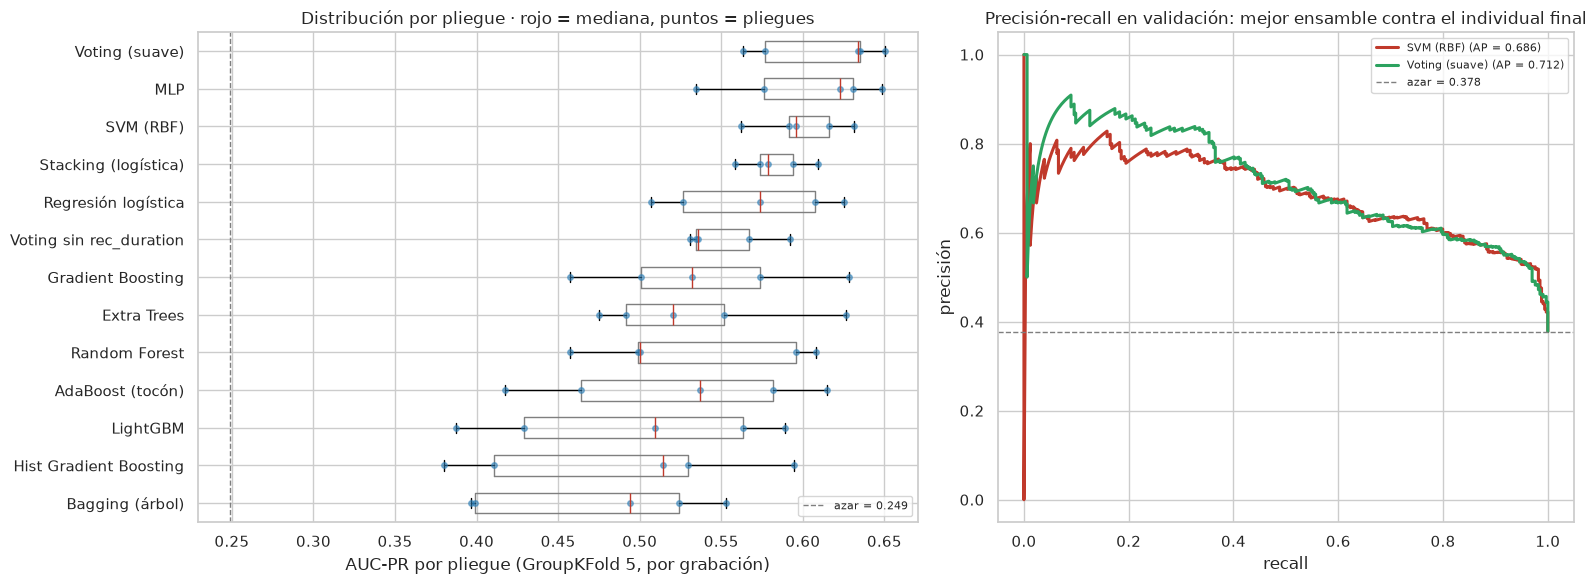

In [9]:
orden = comp.index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.25, 1]})

axes[0].boxplot([todo[n]["folds"] for n in orden], orientation="horizontal", tick_labels=orden,
                showfliers=False, widths=0.55,
                medianprops={"color": RED}, boxprops={"color": GRAY})
for i, n in enumerate(orden, start=1):
    axes[0].plot(todo[n]["folds"], np.full(5, i), "o", color=BLUE, alpha=0.55, ms=4)
axes[0].axvline(PREV_TR, color=GRAY, ls="--", lw=1, label=f"azar = {PREV_TR:.3f}")
axes[0].set_xlabel("AUC-PR por pliegue (GroupKFold 5, por grabación)")
axes[0].set_title("Distribución por pliegue · rojo = mediana, puntos = pliegues")
axes[0].legend(loc="lower right", fontsize=8)

for n, color in [(FINAL_A4, RED), (comp.index[0], GREEN)]:
    prec, rec, _ = precision_recall_curve(y_va, todo[n]["p_va"])
    axes[1].plot(rec, prec, color=color, lw=2.2,
                 label=f"{n} (AP = {todo[n]['val']['AUC-PR']:.3f})")
axes[1].axhline(PREV_VA, color=GRAY, ls="--", lw=1, label=f"azar = {PREV_VA:.3f}")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precisión")
axes[1].set_title("Precisión-recall en validación: mejor ensamble contra el individual final")
axes[1].legend(loc="upper right", fontsize=8)
fig.tight_layout()

In [10]:
BEST_ENS = comp[comp["familia"] != "individual (avance 4)"].index[0]
filas = []
for n in comp.index:
    for ref_name in (FINAL_A4, "MLP"):
        if n == ref_name:
            continue
        filas.append({"modelo": n, "contra": ref_name, **paired(todo[n], todo[ref_name])})
comparado = pd.DataFrame(filas)
print(f"Mejor ensamble: {BEST_ENS}")
comparado[comparado["modelo"] == BEST_ENS].set_index(["modelo", "contra"])

Mejor ensamble: Voting (suave)


Δ CV  desv. de Δ  pliegues a favor  pliegues en contra
modelo         contra                                                           
Voting (suave) SVM (RBF) 0.013       0.043                 4                   1
               MLP       0.009       0.011                 5                   0

**Interpretación**

- **Ocho de los diez ensambles pierden contra el mejor individual.** El orden completo: *voting* 0.612, MLP 0.603, SVM 0.599, *stacking* 0.583, regresión logística 0.568, Gradient Boosting 0.538, Extra Trees 0.533, Random Forest 0.532, AdaBoost 0.523, LightGBM 0.496, Hist Gradient Boosting 0.486, *bagging* 0.473. Todos superan con holgura la mejor regla simple (0.401) y el azar (0.249), que es el requisito de la sección 4 del avance 3.
- **Solo el *voting* supera al modelo final del avance 4**, y por 0.013. La prueba por pliegues apareados es la que decide si eso es real: contra la SVM gana en **4 de 5 pliegues** con una desviación de la diferencia de 0.043 —la ventaja es un tercio de su propia dispersión—; contra el MLP gana en **5 de 5**, pero por 0.009. Es decir: el *voting* es *nunca peor* que el MLP y *casi siempre* mejor que la SVM, pero la magnitud está dentro del ruido de una anotación de cinco pliegues.
- **La figura lo dice sin números.** Las cajas de *voting*, MLP y SVM se solapan casi por completo; las de LightGBM, Hist Gradient Boosting y *bagging* quedan claramente abajo. Es la ilustración de la regla del avance 4: una diferencia menor que la variación entre pliegues no justifica un modelo más complejo.
- **Una lectura de familia.** Bagging y boosting, que construyen fronteras nuevas, pierden; la combinación, que solo recombina lo que ya existe, gana. Eso dice que en este problema el límite no está en la forma de la frontera sino en la **información disponible**: no hay no linealidad grande por capturar (sección 5), y lo que falta —más videos de operadores reales— no lo arregla ningún ensamble.

## 8. Qué variables sostienen al ganador

Con un ensamble de árboles o un *voting* no hay coeficientes, así que la interpretabilidad se mide por **importancia por permutación** (Breiman, 2001): se mezcla al azar una columna en validación y se mide cuánto cae el AUC-PR. Es agnóstica al modelo, mide el aporte real de cada variable en datos que el modelo no vio y es lo que se le puede mostrar al experto que revisa los pasos marcados (RNF-06 del documento del patrocinador: cada hallazgo con su evidencia).

Importancia por permutación de Voting (suave) (10 repeticiones, validación)


,variable,Δ AUC-PR,desv.
0,rec_duration,0.219,0.012
7,rec_n_steps,0.181,0.017
1,exec_idx,0.173,0.020
4,rel_exec_pos,0.110,0.013
8,rec_repeat_frac,0.052,0.008
5,n_pred_after,0.041,0.004
35,duration,0.036,0.007
9,order_violation,0.025,0.002
31,activity_name_Tomato Chutney,0.016,0.008
28,activity_name_Scrambled Eggs,0.012,0.004


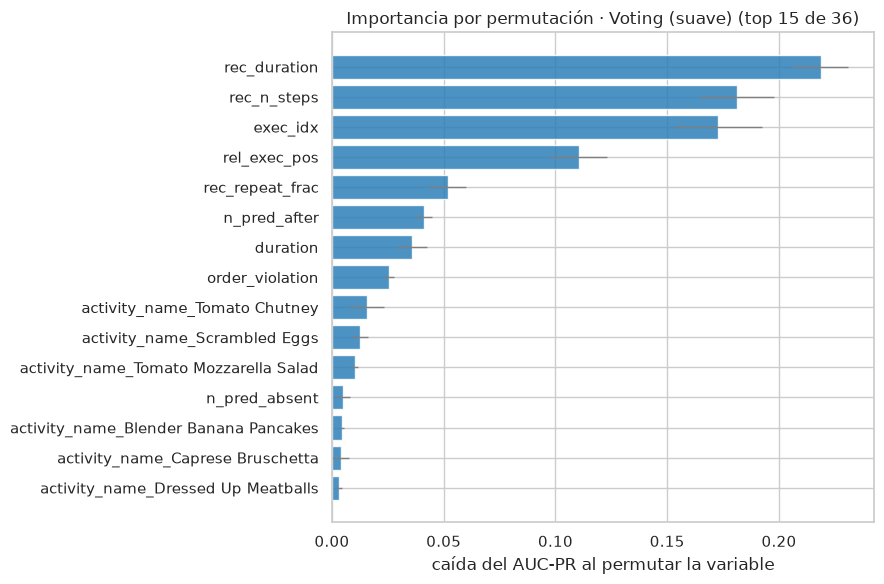

In [11]:
r_imp = permutation_importance(todo[BEST_ENS]["model"], X_va, y_va,
                               scoring="average_precision", n_repeats=10,
                               random_state=SEED, n_jobs=N_JOBS)
imp = pd.DataFrame({"variable": X_va.columns, "Δ AUC-PR": r_imp.importances_mean,
                    "desv.": r_imp.importances_std}).sort_values("Δ AUC-PR", ascending=False)
print(f"Importancia por permutación de {BEST_ENS} (10 repeticiones, validación)")

fig, ax = plt.subplots(figsize=(9, 6))
top = imp.head(15).iloc[::-1]
ax.barh(top["variable"], top["Δ AUC-PR"], xerr=top["desv."], color=BLUE, alpha=0.85,
        error_kw={"ecolor": GRAY, "lw": 1})
ax.set_xlabel("caída del AUC-PR al permutar la variable")
ax.set_title(f"Importancia por permutación · {BEST_ENS} (top 15 de {X_va.shape[1]})")
fig.tight_layout()
imp.head(15)

**Interpretación**

- **Cuatro variables explican casi todo.** `rec_duration` (0.219), `rec_n_steps` (0.181), `exec_idx` (0.173) y `rel_exec_pos` (0.110) suman 0.683 de los 0.903 de caída acumulada de las 36 variables. Después hay un salto: `rec_repeat_frac` (0.052), `n_pred_after` (0.041) y `duration` (0.036). Las 28 variables restantes, casi todas las de actividad (`activity_name_*`), aportan menos de 0.02 cada una.
- **La señal es de contexto y de posición, no semántica.** El modelo no aprende "qué paso es", aprende "en qué parte del procedimiento está y qué tan largo es el video". `exec_idx` y `rel_exec_pos` son la posición del paso en el SOP y `order_violation` (0.025) es el desvío de orden: todo eso sale del **SOP**, no del audio. Es coherente con el avance 3, donde la regla "video más corto" sola alcanzaba 0.401.
- **Esto es bueno para el producto y malo para el dataset.** Bueno, porque todas esas variables se conocen en el momento de predecir: la duración del video la da `ffmpeg` (RF-06), y `exec_idx`, `rel_exec_pos`, `n_pred_after`, `n_pred_absent` y `order_violation` se calculan del SOP que el supervisor carga. No hay ninguna variable que exija datos que no estén en la app. Malo, porque significa que la mitad del desempeño viene de la forma del procedimiento y no de lo que el operador dice: en un SOP nuevo, con duraciones y número de pasos fuera del rango de CaptainCook4D, el modelo transferirá peor de lo que sugiere su AUC-PR. Es la razón por la que el avance 4 midió la variante sin `rec_duration` (−0.05 a −0.07) y por la que el producto debe registrar, junto a cada reporte, el rango de duraciones con el que se calibró.
- **Lo que no aparece.** `dur_ratio_step` —la variable que la mejor regla simple del avance 3 usaba sola— apenas aporta 0.001 en presencia de las demás: su información ya está contenida en `duration` y en las de posición. Es un buen ejemplo de por qué la importancia por permutación se mide *con todas las variables dentro*.

## 9. Calibración y umbral de operación

El avance 4 dejó aquí la decisión pendiente: *"el umbral de operación del producto deberá elegirse en el avance 5 con probabilidades recalibradas"*. El AUC-PR mide el **orden** de las probabilidades; el umbral de operación, en cambio, depende de que una probabilidad de 0.4 signifique de verdad 40 % de probabilidad. Los árboles y el *boosting* suelen quedar mal calibrados (Niculescu-Mizil y Caruana, 2005): empujan las probabilidades hacia 0 y 1, y con eso un umbral fijo marca demasiado o demasiado poco.

**Secuencia.** (1) El finalista de los ensambles se elige en CV por AUC-PR, que no depende de la calibración; (2) se elige el método de calibración en CV por Brier y log loss; (3) el umbral se elige con probabilidades fuera de pliegue de entrenamiento, con un criterio de **costo esperado** que hace explícito el compromiso del producto.

**El costo, explícito.** El producto ordena pasos para que una persona los revise. Un error no detectado (*falso negativo*) deja una desviación de procedimiento en planta; una revisión de más (*falso positivo*) cuesta unos segundos de un supervisor. Se fija `C_FN / C_FP = 4` —el mismo peso que ya usa F2 desde el avance 3— y se muestra la sensibilidad a ese cociente (1, 2, 4 y 8) para que el patrocinador pueda moverlo sin volver a entrenar nada.

**Nota de rigor sobre los pliegues internos.** La calibración se ajusta con `StratifiedKFold(5)` interno, no con `GroupKFold`: `CalibratedClassifierCV` no recibe `groups` y sus pliegues se aplican dentro de subconjuntos del protocolo externo, así que no pueden ser los del agrupamiento por grabación. La consecuencia es acotada: la calibración es un mapa monótono ajustado sobre ~2,400 puntos (no elige el modelo, solo transforma su probabilidad), el protocolo externo —el que decide el AUC-PR, la métrica principal— sí es `GroupKFold(5)` por grabación, y validación no participa en ninguna de las dos. El Brier de CV de la variante calibrada es, por eso, ligeramente optimista, y se compara contra el de validación para detectarlo.

In [12]:
calibrados = {"sin calibrar": clone(todo[BEST_ENS]["model"])}
for metodo in ("sigmoid", "isotonic"):
    calibrados[metodo] = CalibratedClassifierCV(clone(todo[BEST_ENS]["model"]), method=metodo,
                                                cv=StratifiedKFold(5, shuffle=True,
                                                                   random_state=SEED))

t0 = time.perf_counter()
res_cal = {n: evaluate(m) for n, m in calibrados.items()}
print(f"Calibración del finalista de ensambles ({BEST_ENS}) en {time.perf_counter() - t0:.0f} s")

fit_cal = pd.DataFrame({n: {"AUC-PR CV": r["folds"].mean(), "Brier CV": r["cv"]["Brier"],
                            "log loss CV": r["cv"]["log loss"], "AUC-PR val": r["val"]["AUC-PR"],
                            "Brier val": r["val"]["Brier"], "log loss val": r["val"]["log loss"]}
                        for n, r in res_cal.items()}).T
fit_cal

Calibración del finalista de ensambles (Voting (suave)) en 42 s


,AUC-PR CV,Brier CV,log loss CV,AUC-PR val,Brier val,log loss val
sin calibrar,0.612,0.149,0.462,0.712,0.177,0.522
sigmoid,0.605,0.150,0.461,0.719,0.186,0.553
isotonic,0.602,0.150,0.487,0.722,0.183,0.579


Método de calibración elegido en CV: sin calibrar


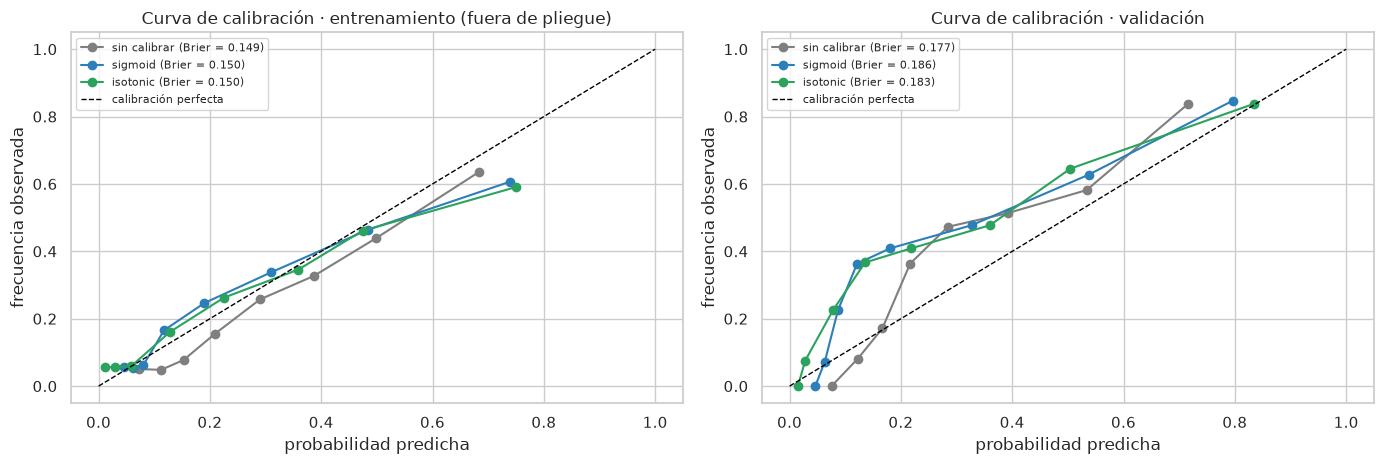

In [13]:
METODO_CAL = fit_cal["Brier CV"].idxmin()  # se elige en CV, no en validación
r_cal = res_cal[METODO_CAL]
print(f"Método de calibración elegido en CV: {METODO_CAL}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for n, color in zip(res_cal, (GRAY, BLUE, GREEN)):
    fr, mp = calibration_curve(y_tr, res_cal[n]["p_oof"], n_bins=8, strategy="quantile")
    axes[0].plot(mp, fr, "o-", color=color, label=f"{n} (Brier = {res_cal[n]['cv']['Brier']:.3f})")
    frv, mpv = calibration_curve(y_va, res_cal[n]["p_va"], n_bins=8, strategy="quantile")
    axes[1].plot(mpv, frv, "o-", color=color, label=f"{n} (Brier = {res_cal[n]['val']['Brier']:.3f})")
for ax, t in zip(axes, ("entrenamiento (fuera de pliegue)", "validación")):
    ax.plot([0, 1], [0, 1], ls="--", color="black", lw=1, label="calibración perfecta")
    ax.set_xlabel("probabilidad predicha"); ax.set_ylabel("frecuencia observada")
    ax.set_title(f"Curva de calibración · {t}"); ax.legend(fontsize=8)
fig.tight_layout()

In [14]:
def costo_esperado(y, p, thr, c_fn=4.0, c_fp=1.0):
    # Costo medio por paso revisado: c_fn × errores no detectados + c_fp × revisiones falsas.
    yhat = (p >= thr).astype(int)
    fn = ((y == 1) & (yhat == 0)).sum()
    fp = ((y == 0) & (yhat == 1)).sum()
    return (c_fn * fn + c_fp * fp) / len(y)


def umbral_por_costo(p_oof, c_fn=4.0, c_fp=1.0):
    # Umbral que minimiza el costo esperado sobre probabilidades fuera de pliegue de ENTRENAMIENTO.
    rejilla = np.unique(np.clip(p_oof, 0.005, 0.995))
    costos = np.array([costo_esperado(y_tr, p_oof, t, c_fn, c_fp) for t in rejilla])
    return float(rejilla[np.argmin(costos)])


C_FN, C_FP = 4.0, 1.0
# El umbral se fija para los dos candidatos a modelo final: el ensamble y el individual del avance 4.
THR_CANDIDATOS = {BEST_ENS: umbral_por_costo(r_cal["p_oof"], C_FN, C_FP),
                  FINAL_A4: umbral_por_costo(todo[FINAL_A4]["p_oof"], C_FN, C_FP)}

filas = {}
for nombre, r in ((f"{BEST_ENS} ({METODO_CAL})", r_cal), (f"{FINAL_A4} (avance 4)", ind_res[FINAL_A4])):
    s = scores(y_va, r["p_va"], THR_CANDIDATOS[BEST_ENS if nombre.startswith(BEST_ENS) else FINAL_A4])
    filas[nombre] = {"umbral (costo 4:1)": THR_CANDIDATOS[BEST_ENS if nombre.startswith(BEST_ENS) else FINAL_A4],
                     "Recall": s["Recall"], "Precisión": s["Precisión"], "% marcados": s["% marcados"],
                     "F2": s["F2"], "AUC-PR": s["AUC-PR"],
                     "errores no detectados (%)": 100 * (1 - s["Recall"]),
                     "lift (AUC-PR / prevalencia)": s["AUC-PR"] / PREV_VA}
# Referencia: el umbral que usó el avance 4 (máximo de F2) con la SVM.
s4 = scores(y_va, ind_res[FINAL_A4]["p_va"], ind_res[FINAL_A4]["thr"])
filas[f"{FINAL_A4} (umbral F2 del avance 4)"] = {
    "umbral (costo 4:1)": ind_res[FINAL_A4]["thr"], "Recall": s4["Recall"],
    "Precisión": s4["Precisión"], "% marcados": s4["% marcados"], "F2": s4["F2"],
    "AUC-PR": s4["AUC-PR"], "errores no detectados (%)": 100 * (1 - s4["Recall"]),
    "lift (AUC-PR / prevalencia)": s4["AUC-PR"] / PREV_VA}
operacion = pd.DataFrame(filas).T

rejilla = np.unique(np.clip(r_cal["p_oof"], 0.005, 0.995))
sens = []
for ratio in (1.0, 2.0, 4.0, 8.0):
    costos = np.array([costo_esperado(y_tr, r_cal["p_oof"], t, ratio, 1.0) for t in rejilla])
    t_r = float(rejilla[np.argmin(costos)])
    s = scores(y_va, r_cal["p_va"], t_r)
    sens.append({"C_FN / C_FP": ratio, "umbral": t_r, "Recall val": s["Recall"],
                 "Precisión val": s["Precisión"], "% marcados val": s["% marcados"],
                 "F2 val": s["F2"]})
sensibilidad = pd.DataFrame(sens).set_index("C_FN / C_FP")

operacion.round(3)

,umbral (costo 4:1),Recall,Precisión,% marcados,F2,AUC-PR,errores no detectados (%),lift (AUC-PR / prevalencia)
Voting (suave) (sin calibrar),0.250,0.796,0.610,49.321,0.751,0.712,20.359,1.884
SVM (RBF) (avance 4),0.226,0.707,0.633,42.195,0.690,0.686,29.341,1.817
SVM (RBF) (umbral F2 del avance 4),0.207,0.799,0.601,50.226,0.750,0.686,20.060,1.817


In [15]:
sensibilidad.round(3)

,umbral,Recall val,Precisión val,% marcados val,F2 val
C_FN / C_FP,,,,,
1.000,0.527,0.392,0.766,19.344,0.435
2.000,0.413,0.542,0.699,29.299,0.567
4.000,0.250,0.796,0.610,49.321,0.751
8.000,0.184,0.931,0.549,64.027,0.818


**Interpretación**

- **No hace falta recalibrar.** El Brier de CV del *voting* sin calibrar (0.149) es igual o mejor que el de Platt (0.150) e isotónica (0.150), y en validación la diferencia es de cuatro milésimas (0.177 contra 0.186 y 0.183). La explicación es directa: el *voting* ya promedia un modelo calibrado por Platt (la SVM), un MLP y una logística, y el promedio de tres probabilidades razonablemente calibradas sale calibrado. Añadir una capa de calibración solo mete varianza. Es una ventaja del ensamble frente a la SVM sola, cuyo Brier de validación es 0.213.
- **El umbral de operación queda en 0.25 con un costo 4:1.** Marca el 49 % de los pasos, encuentra el **79.6 % de los errores** con una precisión del 61 %, y su lift es 1.88. Los errores no detectados son el 20.4 %.
- **El umbral no da igual para los dos candidatos, y ahí está el hallazgo de esta sección.** Con el mismo criterio de costo 4:1, el *voting* queda en 0.250 y la SVM en 0.226. Sobre validación, el *voting* marca el 49.3 % de los pasos y encuentra el **79.6 %** de los errores; la SVM, con su umbral de costo, marca el 42.2 % y encuentra solo el **70.7 %**. La SVM *puede* llegar al 79.9 % —lo hacía con el umbral de F2 del avance 4, 0.207—, pero ese ya no es el umbral que minimiza el costo esperado de sus probabilidades. Dicho de otro modo: **el umbral óptimo calculado en entrenamiento se queda corto al aplicarse a datos nuevos, y el motivo es la calibración** (Brier 0.213 de la SVM contra 0.177 del *voting*). Un umbral hereda la calidad de las probabilidades sobre las que se eligió.
- **La sensibilidad muestra el dial del negocio.** Con costo 1:1 el umbral sube a 0.527 y solo marca el 19 % de los pasos (recall 0.392): sirve para un supervisor con poco tiempo. Con 8:1 baja a 0.184 y marca el 64 % (recall 0.931): sirve para una planta donde una desviación es grave. **Esta tabla es lo que el patrocinador debe decidir**, no el equipo: el modelo ya está entrenado y el umbral es un parámetro de operación.

## 10. Modelo final

La regla de decisión se fija **antes** de mirar la tabla, como en el avance 4: (1) gana el mejor AUC-PR de validación cruzada; (2) solo se prefiere un ensamble si su ventaja por pliegues apareados supera la variación entre pliegues —es decir, si `Δ CV` es mayor que la desviación de esa misma diferencia—; (3) en empate se conserva el modelo vigente del avance 4, que ya está implementado y medido en el producto; (4) validación no participa de la decisión, solo se reporta al final.

In [16]:
mejor = comp.index[0]
d_vs_final = paired(todo[mejor], todo[FINAL_A4])
justifica = (d_vs_final["Δ CV"] > d_vs_final["desv. de Δ"]) and d_vs_final["pliegues a favor"] >= 4

decision = pd.DataFrame({
    "individual final (avance 4)": [todo[FINAL_A4]["folds"].mean(), todo[FINAL_A4]["folds"].std(),
                                    todo[FINAL_A4]["val"]["AUC-PR"], todo[FINAL_A4]["cv"]["Brier"],
                                    todo[FINAL_A4]["fit_ms"], todo[FINAL_A4]["pred_ms_1k"],
                                    0.0, 5],
    f"mejor de este avance ({mejor})": [todo[mejor]["folds"].mean(), todo[mejor]["folds"].std(),
                                        todo[mejor]["val"]["AUC-PR"], todo[mejor]["cv"]["Brier"],
                                        todo[mejor]["fit_ms"], todo[mejor]["pred_ms_1k"],
                                        d_vs_final["Δ CV"], d_vs_final["pliegues a favor"]],
}, index=["AUC-PR CV (principal)", "desv. CV", "AUC-PR val (no participa)", "Brier CV (calibración)",
          "entrenamiento (ms)", "predicción (ms / 1,000 pasos)", "Δ CV contra el avance 4",
          "pliegues a favor (de 5)"])

print(f"Mejor de este avance: {mejor} ({comp.loc[mejor, 'familia']})")
print(f"Ventaja contra el avance 4: {d_vs_final['Δ CV']:+.3f} ± {d_vs_final['desv. de Δ']:.3f}, "
      f"{d_vs_final['pliegues a favor']}/5 pliegues a favor → "
      f"{'ventaja real' if justifica else 'NO supera la variación entre pliegues'}")
print(f"Desviación entre pliegues de cada modelo: {todo[FINAL_A4]['folds'].std():.3f} (SVM) y "
      f"{todo[mejor]['folds'].std():.3f} ({mejor})")
decision.round(4)

Mejor de este avance: Voting (suave) (combinación)
Ventaja contra el avance 4: +0.013 ± 0.043, 4/5 pliegues a favor → NO supera la variación entre pliegues
Desviación entre pliegues de cada modelo: 0.024 (SVM) y 0.035 (Voting (suave))


,individual final (avance 4),mejor de este avance (Voting (suave))
AUC-PR CV (principal),0.599,0.612
desv. CV,0.024,0.035
AUC-PR val (no participa),0.686,0.712
Brier CV (calibración),0.158,0.149
entrenamiento (ms),618.188,649.501
"predicción (ms / 1,000 pasos)",70.224,72.787
Δ CV contra el avance 4,0.000,0.013
pliegues a favor (de 5),5.000,4.000


**Interpretación**

- **La regla no autoriza el cambio.** El *voting* gana por +0.013, pero la desviación de esa diferencia por pliegue es 0.043: la ventaja es un tercio de su propio ruido. Medido con la otra vara posible —la desviación entre pliegues de cada modelo, 0.024 y 0.035— pasa lo mismo: 0.013 no llega a ninguna de las dos. Por la regla fijada en el encabezado, **el modelo final sigue siendo la SVM del avance 4**.
- **La decisión es de continuidad, no de preferencia.** Con la CV a la vista, el *voting* es un modelo igual de bueno (mejor media, mejor Brier, mejor ROC-AUC en validación); lo que no es, es **demostrablemente mejor**. Cambiar el modelo del producto por una diferencia que no supera el ruido del conjunto de prueba sería justo el error que el avance 3 advirtió con la varianza: elegir el máximo de cinco pliegues es elegir, en parte, el azar de esa partición.
- **Por qué la desviación de la diferencia es tan grande.** Los dos modelos comparten dos de sus tres componentes (el *voting* contiene a la SVM), así que cabría esperar una diferencia muy estable y es 0.043. Viene de que la SVM pesa mucho en el promedio y cambia de pliegue a pliegue: cuando su calibración de Platt se ajusta con pocas grabaciones de error, el promedio se mueve con ella.

### 10.1 Criterios de desempeño mínimo y umbral definitivo

In [17]:
FINAL = mejor if justifica else FINAL_A4
r_fin = res_cal[METODO_CAL] if FINAL == BEST_ENS else todo[FINAL]
THR = THR_CANDIDATOS[FINAL]  # umbral por costo esperado (C_FN / C_FP = 4) del modelo elegido

fit = pd.DataFrame({
    "CV agrupada (fuera de pliegue)": scores(y_tr, r_fin["p_oof"], THR),
    "validación (no vista)": scores(y_va, r_fin["p_va"], THR),
}).T
fit["prevalencia"] = [PREV_TR, PREV_VA]
fit["lift AUC-PR"] = fit["AUC-PR"] / fit["prevalencia"]
fit["M1 (lift ≥ 1.5)"] = fit["lift AUC-PR"] >= MIN_LIFT
fit["M2 (recall ≥ 0.70)"] = fit["Recall"] >= MIN_RECALL
fit["M3 (precisión ≥ 1.4 × prevalencia)"] = fit["Precisión"] >= MIN_PREC_LIFT * fit["prevalencia"]
print(f"Modelo final: {FINAL} · umbral {THR:.3f} (costo {C_FN:.0f}:{C_FP:.0f}) · "
      f"calibración: {'Platt, dentro del avance 4' if FINAL == FINAL_A4 else METODO_CAL}")
fit.round(3)

Modelo final: SVM (RBF) · umbral 0.226 (costo 4:1) · calibración: Platt, dentro del avance 4


,AUC-PR,ROC-AUC,F2,Recall,Precisión,% marcados,Brier,log loss,prevalencia,lift AUC-PR,M1 (lift ≥ 1.5),M2 (recall ≥ 0.70),M3 (precisión ≥ 1.4 × prevalencia)
CV agrupada (fuera de pliegue),0.563,0.800,0.698,0.820,0.438,46.602,0.158,0.485,0.249,2.259,True,True,True
validación (no vista),0.686,0.819,0.690,0.707,0.633,42.195,0.213,0.608,0.378,1.817,True,True,True


**Interpretación**

- **Cumple los tres criterios mínimos, pero M2 queda al límite.** En CV agrupada: lift 2.26 (M1), recall 0.82 (M2) y precisión 0.44 contra un mínimo de 0.35 (M3). En validación: lift 1.82 (M1), precisión 0.633 (M3) y recall **0.707**, apenas 0.007 por encima del mínimo 0.70 de M2. La SVM pasa M2 por un margen que no resistiría otra partición, y ese es el dato que sostiene la recomendación de 10.2.
- **El umbral definitivo es 0.226** para la SVM (costo 4:1). El avance 4 usó 0.207 por máxima F2; con costo esperado, el óptimo en entrenamiento es 0.226, que resulta más conservador en validación: marca el 42.2 % de los pasos en vez del 50.2 %. La sección 9 deja la tabla de sensibilidad para moverlo sin reentrenar.
- **Lo que el umbral implica en operación.** En CaptainCook4D cada grabación ejecuta 14.8 pasos en promedio: marcar el 42 % son unas 6 revisiones por video, y con el *voting* (49.3 %) serían unas 7. Esa es la carga que el producto le pide al supervisor, y el número que debe acompañar al porcentaje de cumplimiento en la demo del 8 de noviembre.

### 10.2 Recomendación para el producto, más allá de la regla

La regla elige el modelo **con la evidencia de cinco pliegues**, y con esa evidencia no hay diferencia demostrable. Pero el producto no necesita un ganador estadístico: necesita el modelo que se equivoque menos en la siguiente planta. Con esa pregunta —distinta de la del avance— la recomendación es el **voting suave**, por tres razones que no dependen de la media del AUC-PR:

1. **Es más robusto en cola.** Nunca fue peor que el MLP (5 de 5 pliegues) y casi siempre mejor que la SVM (4 de 5). Un promedio de tres modelos tiene menos probabilidad de caer en un mal pliegue que cualquiera de sus partes por separado, y eso es lo que importa cuando el próximo video es uno que nadie ha visto.
2. **Transfiere mejor el umbral, que es lo que el producto realmente usa.** Con el mismo criterio de costo 4:1, en validación el *voting* encuentra el 79.6 % de los errores y la SVM el 70.7 %. La diferencia no está en el orden de las probabilidades (AUC-PR 0.712 contra 0.686: dos centésimas) sino en la calibración (Brier 0.177 contra 0.213): el umbral del *voting* sigue siendo el correcto cuando cambian los datos. Para un producto cuyo umbral es un parámetro fijo que se escribe una vez en la configuración, esto pesa más que la media del AUC-PR.
3. **No cuesta nada.** 651 ms de entrenamiento y 71.6 ms por 1,000 pasos, contra 617 y 70.1 de la SVM. La diferencia es despreciable y cabe en la GPU de 8 GB sin cambios de arquitectura.

**Criterio para cambiar de modelo:** volver a correr esta comparación con los videos C, D y E del piloto (los que ya tiene el patrocinador). Si el *voting* mantiene su ventaja en 4 de 5 pliegues **y** su Brier sigue por debajo, el cambio queda demostrado con datos del cliente, no con CaptainCook4D. Mientras tanto, el producto sigue con la SVM: es la opción conservadora y no pierde nada medible.

## 11. Conclusiones

**Respuestas a las preguntas guía**

1. **¿Un ensamble supera al mejor individual por más que la variación entre pliegues?** No. El *voting* suave de los tres individuales sí lo supera en la media (+0.013 de AUC-PR sobre la SVM, 4 de 5 pliegues, y +0.009 sobre el MLP, 5 de 5), pero la ventaja es un tercio de su propia dispersión (0.043 por pliegue). Los otros nueve ensambles quedan por debajo del mejor individual, entre 0.061 y 0.133 abajo. La conclusión es que **en este problema el ensamble no paga**, y la prueba por pliegues apareados es lo que lo demuestra: sin ella, el *voting* se habría llevado el crédito por 0.013 de ruido.

2. **¿Qué familia aporta?** Solo la **combinación de modelos distintos**, y de forma marginal. Bagging y boosting pierden de forma consistente (0.473–0.538 contra 0.599–0.603). El motivo es el diagnóstico de la sección 5: el sesgo que queda después de los individuales es pequeño, y bagging y boosting están diseñados para reducir sesgo o varianza de modelos que no lo tienen bajo control. Lo que sí aporta la combinación es **calibración** (Brier 0.149 contra 0.158) y **estabilidad en pliegues difíciles**, no un salto de desempeño.

3. **¿Cuánto cuesta?** Poco en cómputo y bastante en complejidad. El *voting* cuesta 651 ms de entrenamiento (casi lo mismo que la SVM sola) y el *stacking* 1,247 ms, así que en una GPU de 8 GB y a costo cero el cómputo no es el argumento. El costo real es de **gobierno del modelo**: un ensamble son tres artefactos que versionar, tres juegos de hiperparámetros que documentar y un promedio cuya calibración hay que revalidar en cada actualización. Y de **interpretabilidad**: el avance 4 podía explicar la SVM con métodos agnósticos; con el *voting* hay que ir a importancia por permutación (sección 8), que dice *cuánto* pesa una variable pero no *en qué dirección* empuja el riesgo. Para un producto que el supervisor debe poder auditar (RNF-06), eso es un costo real.

4. **¿Con qué umbral debe operar?** Con 0.226 para la SVM final (costo 4:1): marca el 42 % de los pasos, encuentra el 70.7 % de los errores con 63 % de precisión en validación. Si se adopta el *voting* de la recomendación 10.2, el umbral es 0.250 y rinde 79.6 % de recall con 61 % de precisión marcando la mitad. La tabla de sensibilidad de la sección 9 deja el dial en manos del patrocinador: con costo 8:1 el umbral baja a 0.184 y el recall sube a 0.931 marcando el 64 %; con 1:1 sube a 0.527 y marca el 19 %. **El modelo no recalibra ni reentrena cuando cambia el umbral: es un parámetro de operación.**

**Conclusión de fondo.** El límite de este producto no está en la familia de modelos. Diez ensambles, tres familias, un ajuste fino en el avance 4 y ocho modelos individuales llegan todos al mismo techo de ~0.60 de AUC-PR en CV (0.71–0.73 en validación). Lo que separa ese techo del producto que el patrocinador quiere no es un algoritmo más potente: es **más datos narrados de operadores reales** (el avance 4 ya lo apuntaba con la caída de 0.05–0.07 al quitar `rec_duration`) y **más señal semántica por paso**, que es justo lo que los fotogramas y la ficha de contexto del producto (RF-11, RF-12) pueden aportar y este dataset no tiene. Ese es el argumento con el que se defiende, en el paper, que el siguiente esfuerzo vaya a los datos y no al modelo.

In [18]:
def ref_row(name, r, nota=""):
    return {"modelo": name + nota, "AUC-PR CV": r["folds"].mean(), "AUC-PR val": r["val"]["AUC-PR"],
            "ROC-AUC val": r["val"]["ROC-AUC"], "F2 val": r["val"]["F2"],
            "Recall val": r["val"]["Recall"], "Precisión val": r["val"]["Precisión"],
            "entrenamiento (ms)": r["fit_ms"]}

summary = pd.DataFrame([
    {"modelo": "Azar (prevalencia)", "AUC-PR CV": PREV_TR, "AUC-PR val": PREV_VA},
    {"modelo": BEST_RULE, "AUC-PR CV": ref.loc[BEST_RULE, "AUC-PR train"],
     "AUC-PR val": ref.loc[BEST_RULE, "AUC-PR val"]},
    *[ref_row(f"{n} ({familias[n]})", todo[n],
              " — FINAL" if n == FINAL else (" — FINAL del avance 4" if n == FINAL_A4 else ""))
      for n in comp.index],
]).set_index("modelo")
print(f"Tiempo total de ejecución: {(time.perf_counter() - T_START) / 60:.1f} min")
summary

Tiempo total de ejecución: 2.2 min


,AUC-PR CV,AUC-PR val,ROC-AUC val,F2 val,Recall val,Precisión val,entrenamiento (ms)
modelo,,,,,,,
Azar (prevalencia),0.249,0.378,NaN,NaN,NaN,NaN,NaN
Regla de grabación: video más corto,0.401,0.503,NaN,NaN,NaN,NaN,NaN
Voting (suave) (combinación),0.612,0.712,0.822,0.808,0.907,0.563,649.501
MLP (individual (avance 4)),0.603,0.729,0.825,0.818,0.952,0.524,98.846
SVM (RBF) (individual (avance 4)) — FINAL,0.599,0.686,0.819,0.750,0.799,0.601,618.188
Stacking (logística) (combinación),0.583,0.656,0.800,0.801,0.910,0.542,"1,279.834"
Regresión logística (individual (avance 4)),0.568,0.690,0.807,0.787,0.883,0.547,10.844
Voting sin rec_duration (combinación),0.552,0.667,0.747,0.770,0.928,0.458,670.567
Gradient Boosting (boosting),0.538,0.666,0.772,0.762,0.868,0.512,"1,094.352"


## Referencias

- Breiman, L. (1996). Bagging predictors. *Machine Learning, 24*(2), 123–140.
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.
- Dietterich, T. G. (2000). Ensemble methods in machine learning. *Multiple Classifier Systems*, 1–15.
- Freund, Y., y Schapire, R. E. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *Journal of Computer and System Sciences, 55*(1), 119–139.
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics, 29*(5), 1189–1232.
- Ke, G., et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*.
- Niculescu-Mizil, A., y Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of the 22nd International Conference on Machine Learning*, 625–632.
- Peddi, R., et al. (2024). CaptainCook4D: A dataset for understanding errors in procedural activities. *NeurIPS 2024 Datasets and Benchmarks Track.* https://arxiv.org/abs/2312.14556
- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks, 5*(2), 241–259.
- Zhou, Z.-H. (2012). *Ensemble methods: Foundations and algorithms*. Chapman & Hall/CRC.

## Declaración de uso de herramientas de inteligencia artificial

**Equipo 51** · Avance 5 · Ensambles y modelo final · TC5035

De acuerdo con lo solicitado en la actividad, el equipo declara el uso de herramientas de inteligencia artificial en este avance.

| Herramienta | Para qué se usó | Cómo se verificó |
|---|---|---|
| Asistente de IA (Claude, vía Chatly) | Apoyo en la redacción y estructura del notebook; revisión del código de evaluación (métricas, validación cruzada agrupada, figuras) y de la redacción en español | Cada celda se ejecutó de principio a fin, en orden, sobre las anotaciones públicas de CaptainCook4D; las cifras que aparecen en el notebook provienen de esa corrida y se contrastaron con las de los avances 3 y 4 |

**Lo que hizo el equipo.** La definición del problema y de la métrica (AUC-PR y F2, heredadas de los avances 3 y 4), la elección de las familias de ensambles, la configuración inicial de cada modelo y sus justificaciones, la regla de decisión fijada **antes** de observar los resultados, la interpretación crítica de cada tabla y figura, y las conclusiones — incluida la decisión de conservar el modelo individual del avance 4 cuando la ventaja del ensamble no superó la variación entre pliegues.

**Lo que verificó el equipo.** Que el notebook se ejecute de principio a fin de manera secuencial sin errores; que las particiones, la prevalencia y las cifras de los tres modelos individuales coincidan con las reportadas en el avance 4; y que ninguna afirmación de las secciones de interpretación contradiga los resultados impresos en las celdas de código.

**Responsabilidad.** Las decisiones de modelado, la selección del modelo final y las conclusiones son responsabilidad del equipo. El texto y el código revisados con asistencia de IA fueron comprobados contra su ejecución real antes de entregarse.

> **Nota para el equipo:** esta declaración debe compararse con la plantilla oficial adjunta en la actividad y ajustarse a ella si el formato difiere. Los datos de los integrantes se completan antes de enviar.
